<a href="https://colab.research.google.com/github/ChrisX215/Visi-Komputer-2026/blob/main/Praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum D1 – Memulai Klasifikasi Gambar dengan Dataset Sederhana

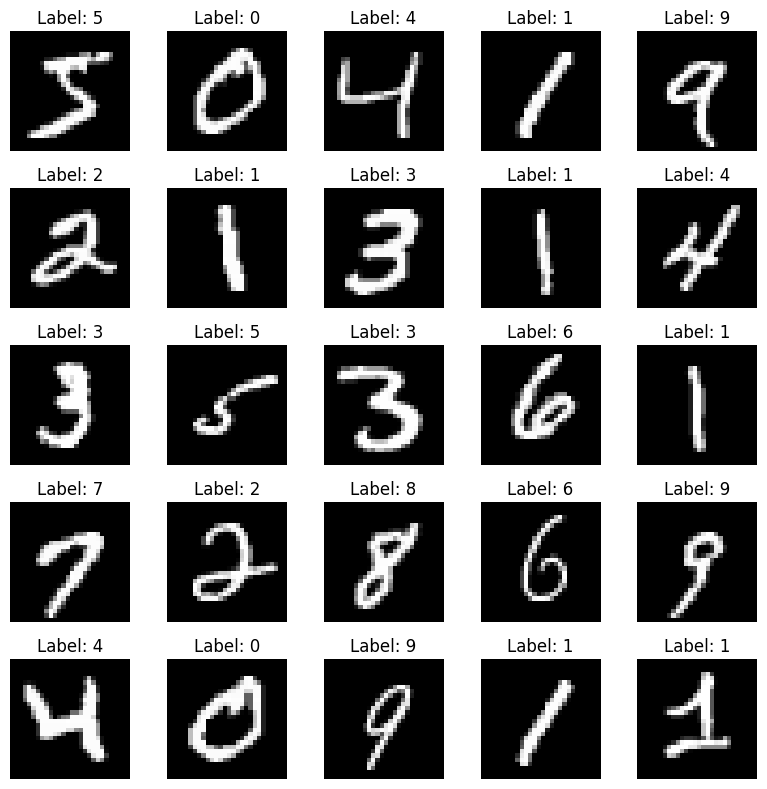

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist

# Load dataset MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()

plt.figure(figsize=(8, 8))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Praktikum D2 – Klasifikasi Gambar dengan Model Machine Learning Tradisional

In [8]:
from sklearn import svm
from sklearn.metrics import accuracy_score

# Flatten
x_train_flat = x_train.reshape(len(x_train), -1) / 255.0
x_test_flat = x_test.reshape(len(x_test), -1) / 255.0

# SVM (Modifikasi Tugas Kecil: kernel diubah menjadi 'rbf')
clf = svm.SVC(kernel='rbf', gamma='scale')
clf.fit(x_train_flat[:5000], y_train[:5000]) # menggunakan subset karena SVM berat

y_pred = clf.predict(x_test_flat)
print("Akurasi (Kernel RBF):", accuracy_score(y_test, y_pred))

Akurasi (Kernel RBF): 0.9513


# Praktikum D3 – Membangun CNN Sederhana

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.9606 - loss: 0.1276 - val_accuracy: 0.9872 - val_loss: 0.0439
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9871 - loss: 0.0422 - val_accuracy: 0.9878 - val_loss: 0.0383
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9916 - loss: 0.0269 - val_accuracy: 0.9888 - val_loss: 0.0380
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9935 - loss: 0.0191 - val_accuracy: 0.9900 - val_loss: 0.0398
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9954 - loss: 0.0148 - val_accuracy: 0.9852 - val_loss: 0.0598


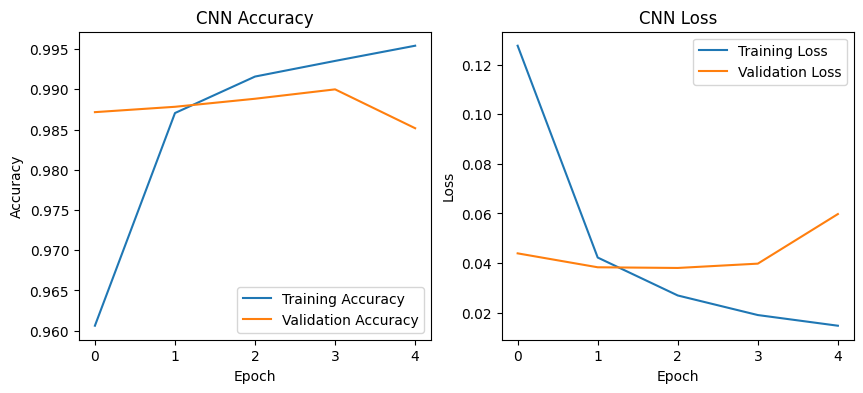

In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

# Load kembali data MNIST agar menimpa data CIFAR-10 di memori
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Sekarang proses reshape akan berhasil
x_train_cnn = x_train.reshape(-1,28,28,1) / 255.0
x_test_cnn = x_test.reshape(-1,28,28,1) / 255.0

model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train_cnn, y_train, epochs=5, validation_split=0.1)

# ===== Plot history =====
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Praktikum D4 – Eksperimen dengan Dataset Lebih Kompleks (CIFAR-10)

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.3341 - loss: 1.7836 - val_accuracy: 0.4680 - val_loss: 1.4846
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.4384 - loss: 1.5288 - val_accuracy: 0.5602 - val_loss: 1.2653
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4920 - loss: 1.4008 - val_accuracy: 0.6110 - val_loss: 1.1393
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5270 - loss: 1.3164 - val_accuracy: 0.6080 - val_loss: 1.1483
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5460 - loss: 1.2656 - val_accuracy: 0.6268 - val_loss: 1.0807
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5685 - loss: 1.2068 - val_accuracy: 0.6522 - val_loss: 1.0245
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5882 - loss: 1.1600 - val_accuracy: 0.6590 - val_loss: 0.9891
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6011 - loss: 1.1190 -

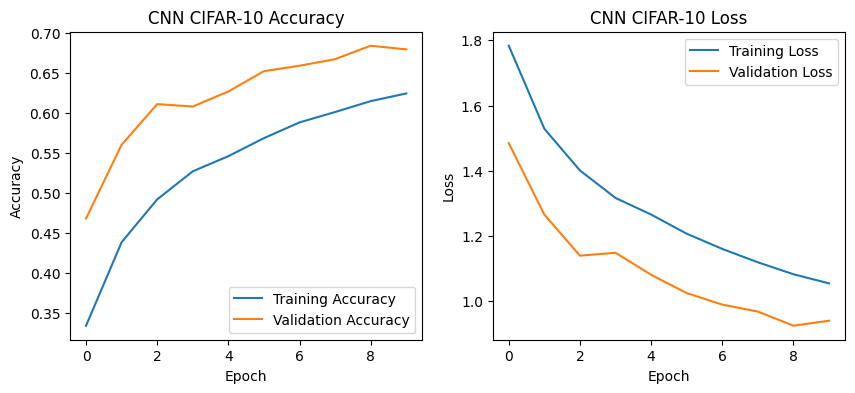

In [4]:
from tensorflow.keras.datasets import cifar10
from tensorflow.keras import layers, models # Tambahan import agar tidak NameError
import matplotlib.pyplot as plt             # Tambahan import untuk plot grafik

# Load dan normalisasi data CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train, x_test = x_train/255.0, x_test/255.0

# Membangun model sesuai modul
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Melatih model (epochs=10 sesuai modul)
history = model.fit(x_train, y_train, epochs=10, validation_split=0.1)

# ===== Plot history =====
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN CIFAR-10 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN CIFAR-10 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Praktikum D5 – Transfer Learning dengan Model Pra-Latih

Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 26s 14ms/step - accuracy: 0.6097 - loss: 1.1261 - val_accuracy: 0.6866 - val_loss: 0.9291
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - accuracy: 0.7172 - loss: 0.8285 - val_accuracy: 0.7114 - val_loss: 0.8463
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - accuracy: 0.7493 - loss: 0.7301 - val_accuracy: 0.7240 - val_loss: 0.8201
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - accuracy: 0.7750 - loss: 0.6556 - val_accuracy: 0.7380 - val_loss: 0.7850
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - accuracy: 0.7966 - loss: 0.5897 - val_accuracy: 0.7514 - val_loss: 0.7793


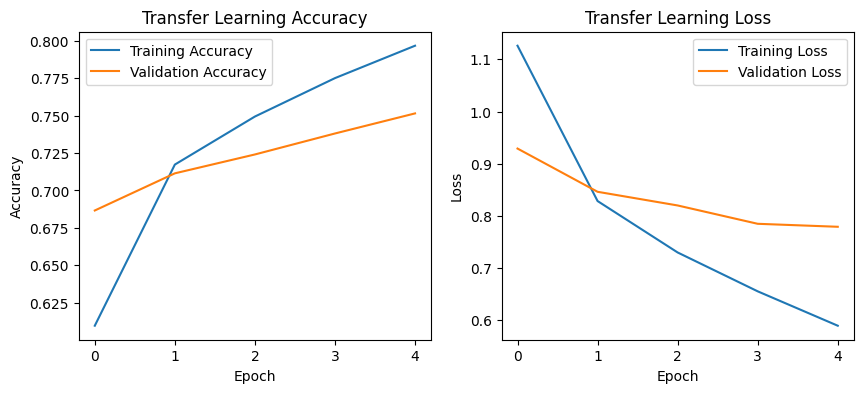

In [6]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Load base model VGG16
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(32,32,3))

# Secara bawaan, seluruh lapisan base_model dibekukan (sesuai modul D5 awal)
base_model.trainable = False

# --- TUGAS KECIL: Fine-tuning ---
# Jika mau melihat pengaruh Tugas Kecil (mengaktifkan beberapa layer terakhir),
# jadikan baris di atas komentar (# base_model.trainable = False)
# lalu hapus tanda pagar (#) pada 3 baris kode di bawah ini:

base_model.trainable = True
for layer in base_model.layers[:-4]:
     layer.trainable = False


model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Proses training menggunakan data CIFAR-10 dari Praktikum D4
history = model.fit(x_train, y_train, epochs=5, validation_split=0.1)

# ===== Plot history =====
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Transfer Learning Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Transfer Learning Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Praktikum D6 – Evaluasi dengan Confusion Matrix dan Metrik Lain

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.79      0.80      1000
           1       0.83      0.84      0.83      1000
           2       0.81      0.51      0.62      1000
           3       0.54      0.60      0.57      1000
           4       0.60      0.78      0.68      1000
           5       0.67      0.57      0.62      1000
           6       0.73      0.78      0.76      1000
           7       0.76      0.82      0.79      1000
           8       0.88      0.83      0.85      1000
           9       0.79      0.80      0.80      1000

    accuracy                           0.73     10000
   macro avg       0.74      0.73      0.73     10000
weighted avg       0.74      0.73      0.73     10000



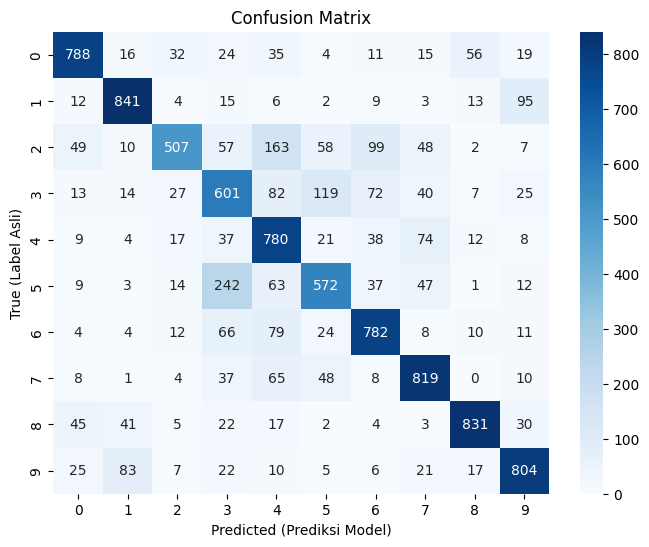

In [7]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt # Tambahan import agar fungsi plot berjalan aman

# Melakukan prediksi menggunakan model pada data pengujian (x_test)
y_pred = model.predict(x_test).argmax(axis=1)

# Menampilkan laporan metrik evaluasi (precision, recall, f1-score, accuracy)
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Membuat matriks konfusi (confusion matrix)
cm = confusion_matrix(y_test, y_pred)

# Menampilkan visualisasi matriks konfusi dengan seaborn heatmap
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted (Prediksi Model)')
plt.ylabel('True (Label Asli)')
plt.title('Confusion Matrix')
plt.show()

# --- TUGAS KECIL ---
# Setelah grafik muncul, amati kotak-kotak di luar garis diagonal utama (kiri atas ke kanan bawah).
# Kotak dengan angka besar (warna lebih gelap) di luar diagonal menunjukkan
# kelas-kelas yang sering salah diklasifikasikan (tertukar) oleh model.

# **Penugasan**

Silakan upload foto angka tulisan tangan (format jpg/png):


Saving angka 5.jpg to angka 5.jpg


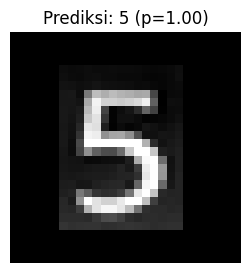

Rekap Prediksi (CNN):
- angka 5.jpg -> 5 (p=0.999)


In [17]:
# ===== 1) Upload file foto tulisan angka =====
from google.colab import files
import numpy as np
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

print("Silakan upload foto angka tulisan tangan (format jpg/png):")
uploaded = files.upload()

# ===== 2) Utilitas Preprocess agar mirip MNIST (28x28) =====
def preprocess_to_mnist_28x28(img_pil):
    img = img_pil.convert('L')
    img = ImageOps.autocontrast(img)
    arr = np.array(img).astype(np.uint8)

    # Invert jika latar terang (agar digit jadi putih, latar gelap seperti MNIST)
    if arr.mean() > 127:
        img = ImageOps.invert(img)
        arr = np.array(img)

    # Binarisasi ringan untuk mencari bounding box digit
    thr = np.mean(arr) * 0.8
    mask = arr > thr
    if mask.any():
        ys, xs = np.where(mask)
        y0, y1 = ys.min(), ys.max()
        x0, x1 = xs.min(), xs.max()
        img = img.crop((x0, y0, x1+1, y1+1))

    # Resize ke 20x20 dengan aspect ratio
    img.thumbnail((20, 20), Image.Resampling.LANCZOS)
    canvas = Image.new('L', (28, 28), color=0)

    # Pad ke 28x28 dan posisikan di tengah
    canvas.paste(img, ((28 - img.size[0]) // 2, (28 - img.size[1]) // 2))

    # Normalisasi ke [0,1] dan tambah channel dim
    arr = np.array(canvas).astype('float32') / 255.0
    arr = arr[..., None]
    return canvas, arr

# ===== 3) Prediksi dengan CNN (Pilihan A) =====
results = []
for fname in uploaded.keys():
    img_pil = Image.open(fname)
    disp, x = preprocess_to_mnist_28x28(img_pil)

    x_batch = np.expand_dims(x, axis=0)
    probs = model.predict(x_batch, verbose=0)[0]
    pred = int(np.argmax(probs))
    conf = float(np.max(probs))
    results.append((fname, pred, conf))

    # Tampilkan hasil
    plt.figure(figsize=(3,3))
    plt.imshow(disp, cmap='gray')
    plt.title(f"Prediksi: {pred} (p={conf:.2f})")
    plt.axis('off')
    plt.show()

# Rekap ringkas
print("Rekap Prediksi (CNN):")
for r in results:
    print(f"- {r[0]} -> {r[1]} (p={r[2]:.3f})")